In [ ]:
import pandas as pd

# Cargar el archivo CSV
df = pd.read_csv('/content/eu_limpio.csv')

# Mostrar las primeras filas del DataFrame
display(df.head())

,ID,Start_Date,End_Date,Duration,Category,Category_Kickstarter,Success,Funding,Funding_IHS,Target,...,Flag_IQR_Duration_Calendar,Flag_IQR_Description,Flag_IQR_Rewards,Flag_IQR_Prev_Success,Flag_IQR_Backed,Flag_IQR_Links,Category_Creative_Arts,Category_Design,Category_Literature_Journalism,Category_Food
0,4,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,2461.23,8.501564,1085.20,...,0,0,0,0,0,0,0,0,0,0
1,7,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,37601.09,11.227935,2170.40,...,0,0,0,0,1,0,0,0,0,0
2,12,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,4531.80,9.112022,732.51,...,0,0,0,0,1,0,0,0,0,0
3,16,2022-02-17,2022-03-07,17,Media & Entertainment,games,1,18787.60,10.534100,5000.00,...,0,0,0,1,0,0,0,0,0,0
4,17,2022-02-04,2022-03-07,31,Media & Entertainment,film & video,0,1451.00,7.973156,3198.00,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
tabla_exito = (
    df["Success"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Success")
    .reset_index(name="Campañas")
)

tabla_exito["Resultado"] = tabla_exito["Success"].map({
    0: "No exitosa",
    1: "Exitosa"
})

tabla_exito["Porcentaje"] = (
    tabla_exito["Campañas"] / len(df) * 100
).round(2)

tabla_exito = tabla_exito[["Resultado", "Campañas", "Porcentaje"]]

display(tabla_exito)

,Resultado,Campañas,Porcentaje
0,No exitosa,417,18.35
1,Exitosa,1855,81.65


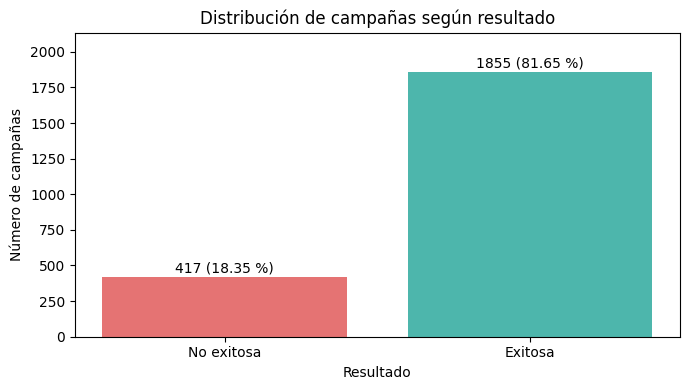

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    tabla_exito["Resultado"],
    tabla_exito["Campañas"],
    color=["#E57373", "#4DB6AC"]
)

for barra, porcentaje in zip(barras, tabla_exito["Porcentaje"]):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 35,
        f"{int(barra.get_height())} ({porcentaje:.2f} %)",
        ha="center"
    )

ax.set_title("Distribución de campañas según resultado")
ax.set_xlabel("Resultado")
ax.set_ylabel("Número de campañas")
ax.set_ylim(0, tabla_exito["Campañas"].max() * 1.15)

plt.tight_layout()
plt.show()

In [ ]:
tabla_categoria = (
    df["Category"]
    .value_counts(dropna=False)
    .rename_axis("Categoría")
    .reset_index(name="Campañas")
)

tabla_categoria["Porcentaje"] = (
    tabla_categoria["Campañas"] / len(df) * 100
).round(2)

display(tabla_categoria)

,Categoría,Campañas,Porcentaje
0,Media & Entertainment,1494,65.76
1,Creative Arts,337,14.83
2,Design,254,11.18
3,Literature & Journalism,159,7.00
4,Food,28,1.23


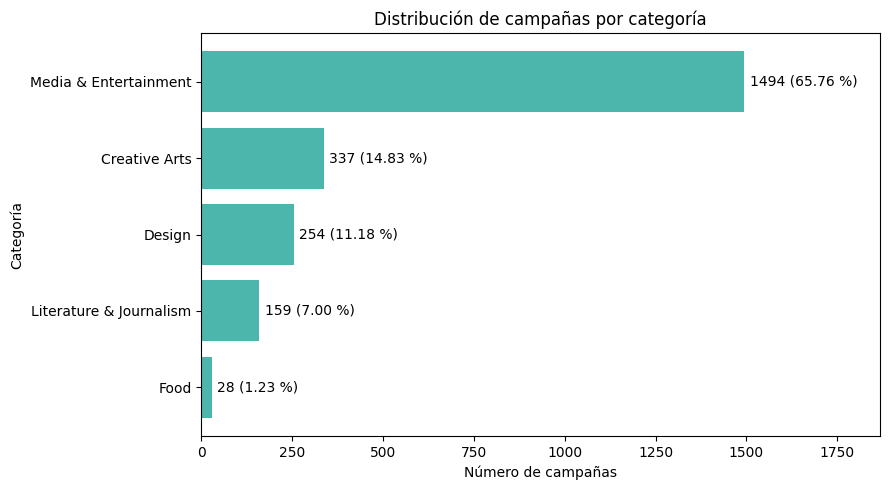

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(
    tabla_categoria["Categoría"],
    tabla_categoria["Campañas"],
    color="#4DB6AC"
)

for barra, porcentaje in zip(barras, tabla_categoria["Porcentaje"]):
    ax.text(
        barra.get_width() + 15,
        barra.get_y() + barra.get_height() / 2,
        f"{int(barra.get_width())} ({porcentaje:.2f} %)",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Distribución de campañas por categoría")
ax.set_xlabel("Número de campañas")
ax.set_ylabel("Categoría")
ax.set_xlim(0, tabla_categoria["Campañas"].max() * 1.25)

plt.tight_layout()
plt.show()

In [ ]:
variables_multimedia = ["Video_Header", "Videos_Bool", "Images_Bool"]

for variable in variables_multimedia:
    tabla = (
        df[variable]
        .value_counts(dropna=False)
        .rename_axis("Valor")
        .reset_index(name="Campañas")
    )

    tabla["Porcentaje"] = (
        tabla["Campañas"] / len(df) * 100
    ).round(2)

    print(f"\n{variable} — 0: No / 1: Sí")
    display(tabla)


Video_Header — 0: No / 1: Sí


,Valor,Campañas,Porcentaje
0,1,1307,57.53
1,0,965,42.47



Videos_Bool — 0: No / 1: Sí


,Valor,Campañas,Porcentaje
0,0,1883,82.88
1,1,389,17.12



Images_Bool — 0: No / 1: Sí


,Valor,Campañas,Porcentaje
0,1,2149,94.59
1,0,123,5.41


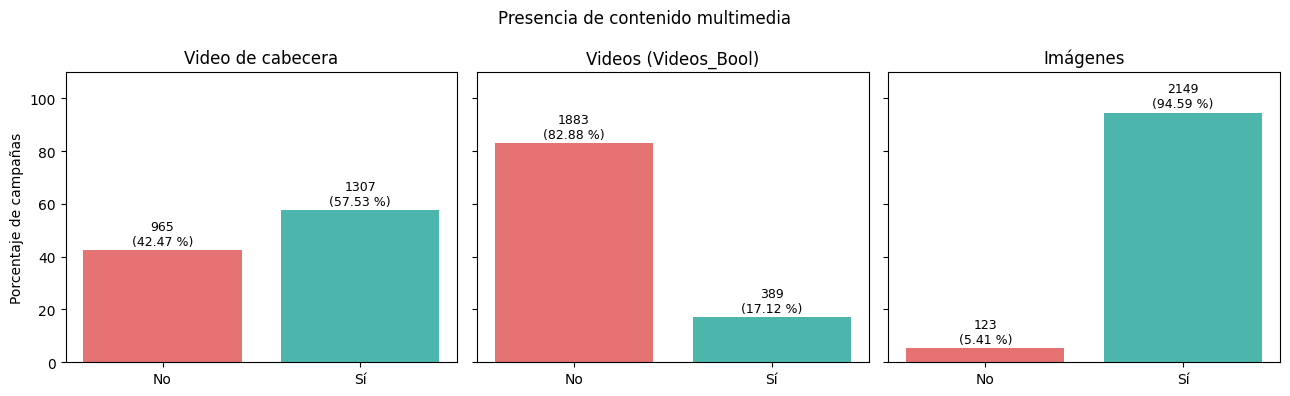

In [ ]:
import matplotlib.pyplot as plt

variables = {
    "Video_Header": "Video de cabecera",
    "Videos_Bool": "Videos (Videos_Bool)",
    "Images_Bool": "Imágenes"
}

fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for ax, (variable, titulo) in zip(ejes, variables.items()):
    conteos = df[variable].value_counts().reindex([0, 1], fill_value=0)
    porcentajes = conteos / len(df) * 100

    barras = ax.bar(
        ["No", "Sí"],
        porcentajes.values,
        color=["#E57373", "#4DB6AC"]
    )

    for barra, cantidad, porcentaje in zip(
        barras, conteos.values, porcentajes.values
    ):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 2,
            f"{cantidad}\n({porcentaje:.2f} %)",
            ha="center",
            fontsize=9
        )

    ax.set_title(titulo)
    ax.set_ylim(0, 110)

ejes[0].set_ylabel("Porcentaje de campañas")
fig.suptitle("Presencia de contenido multimedia")
plt.tight_layout()
plt.show()

In [ ]:
variables_numericas = [
    "Funding",
    "Target",
    "Duration_Calendar",
    "Description",
    "Rewards",
    "Prev_Success",
    "Backed",
    "Links"
]

resumen_numerico = (
    df[variables_numericas]
    .describe()
    .T
    .rename(columns={
        "count": "Datos válidos",
        "mean": "Media",
        "std": "Desviación estándar",
        "min": "Mínimo",
        "25%": "Q1",
        "50%": "Mediana",
        "75%": "Q3",
        "max": "Máximo"
    })
)

display(resumen_numerico.round(2))

,Datos válidos,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo
Funding,2272.0,15166.36,110883.80,0.0,1362.29,3681.44,10146.57,3960285.74
Target,2272.0,8430.72,40128.09,1.0,530.80,2103.20,7417.52,1518980.00
Duration_Calendar,2272.0,29.21,12.20,2.0,21.00,30.00,31.00,60.00
Description,2272.0,15.52,5.99,0.0,11.00,16.00,20.00,43.00
Rewards,2272.0,7.03,4.47,1.0,4.00,6.00,9.00,45.00
Prev_Success,2272.0,2.71,4.86,0.0,0.00,0.00,3.00,29.00
Backed,2272.0,11.83,36.20,0.0,0.00,1.00,8.00,830.00
Links,2272.0,1.39,1.42,0.0,0.00,1.00,2.00,13.00


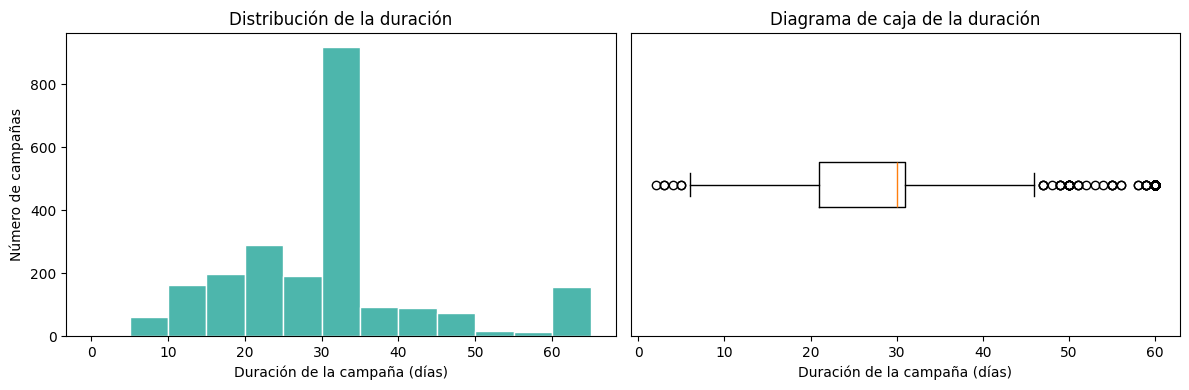

In [ ]:
import matplotlib.pyplot as plt

duracion = df["Duration_Calendar"].dropna()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].hist(
    duracion,
    bins=range(0, 66, 5),
    color="#4DB6AC",
    edgecolor="white"
)
ejes[0].set_title("Distribución de la duración")
ejes[0].set_xlabel("Duración de la campaña (días)")
ejes[0].set_ylabel("Número de campañas")

ejes[1].boxplot(duracion, vert=False)
ejes[1].set_title("Diagrama de caja de la duración")
ejes[1].set_xlabel("Duración de la campaña (días)")
ejes[1].set_yticks([])

plt.tight_layout()
plt.show()

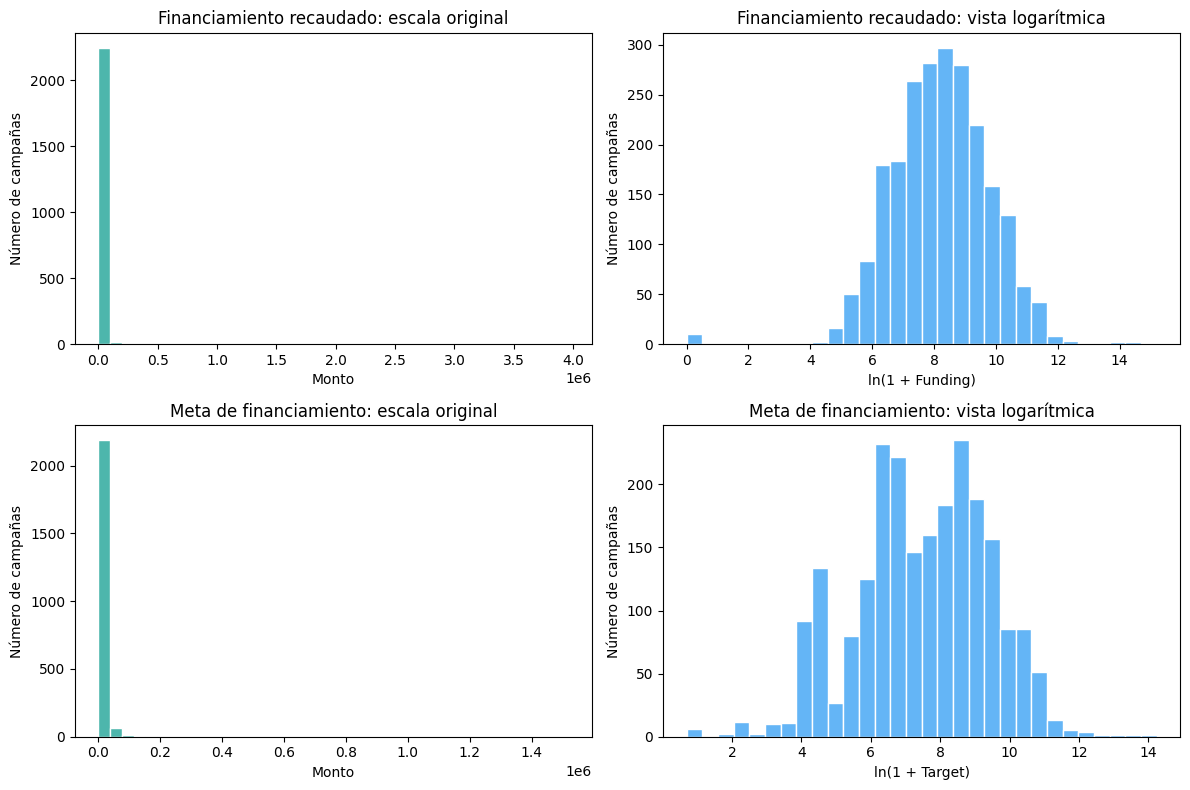

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

variables = {
    "Funding": "Financiamiento recaudado",
    "Target": "Meta de financiamiento"
}

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

for fila, (variable, titulo) in enumerate(variables.items()):
    datos = df[variable].dropna()

    ejes[fila, 0].hist(
        datos, bins=40,
        color="#4DB6AC", edgecolor="white"
    )
    ejes[fila, 0].set_title(f"{titulo}: escala original")
    ejes[fila, 0].set_xlabel("Monto")
    ejes[fila, 0].set_ylabel("Número de campañas")

    ejes[fila, 1].hist(
        np.log1p(datos), bins=30,
        color="#64B5F6", edgecolor="white"
    )
    ejes[fila, 1].set_title(f"{titulo}: vista logarítmica")
    ejes[fila, 1].set_xlabel(f"ln(1 + {variable})")
    ejes[fila, 1].set_ylabel("Número de campañas")

plt.tight_layout()
plt.show()

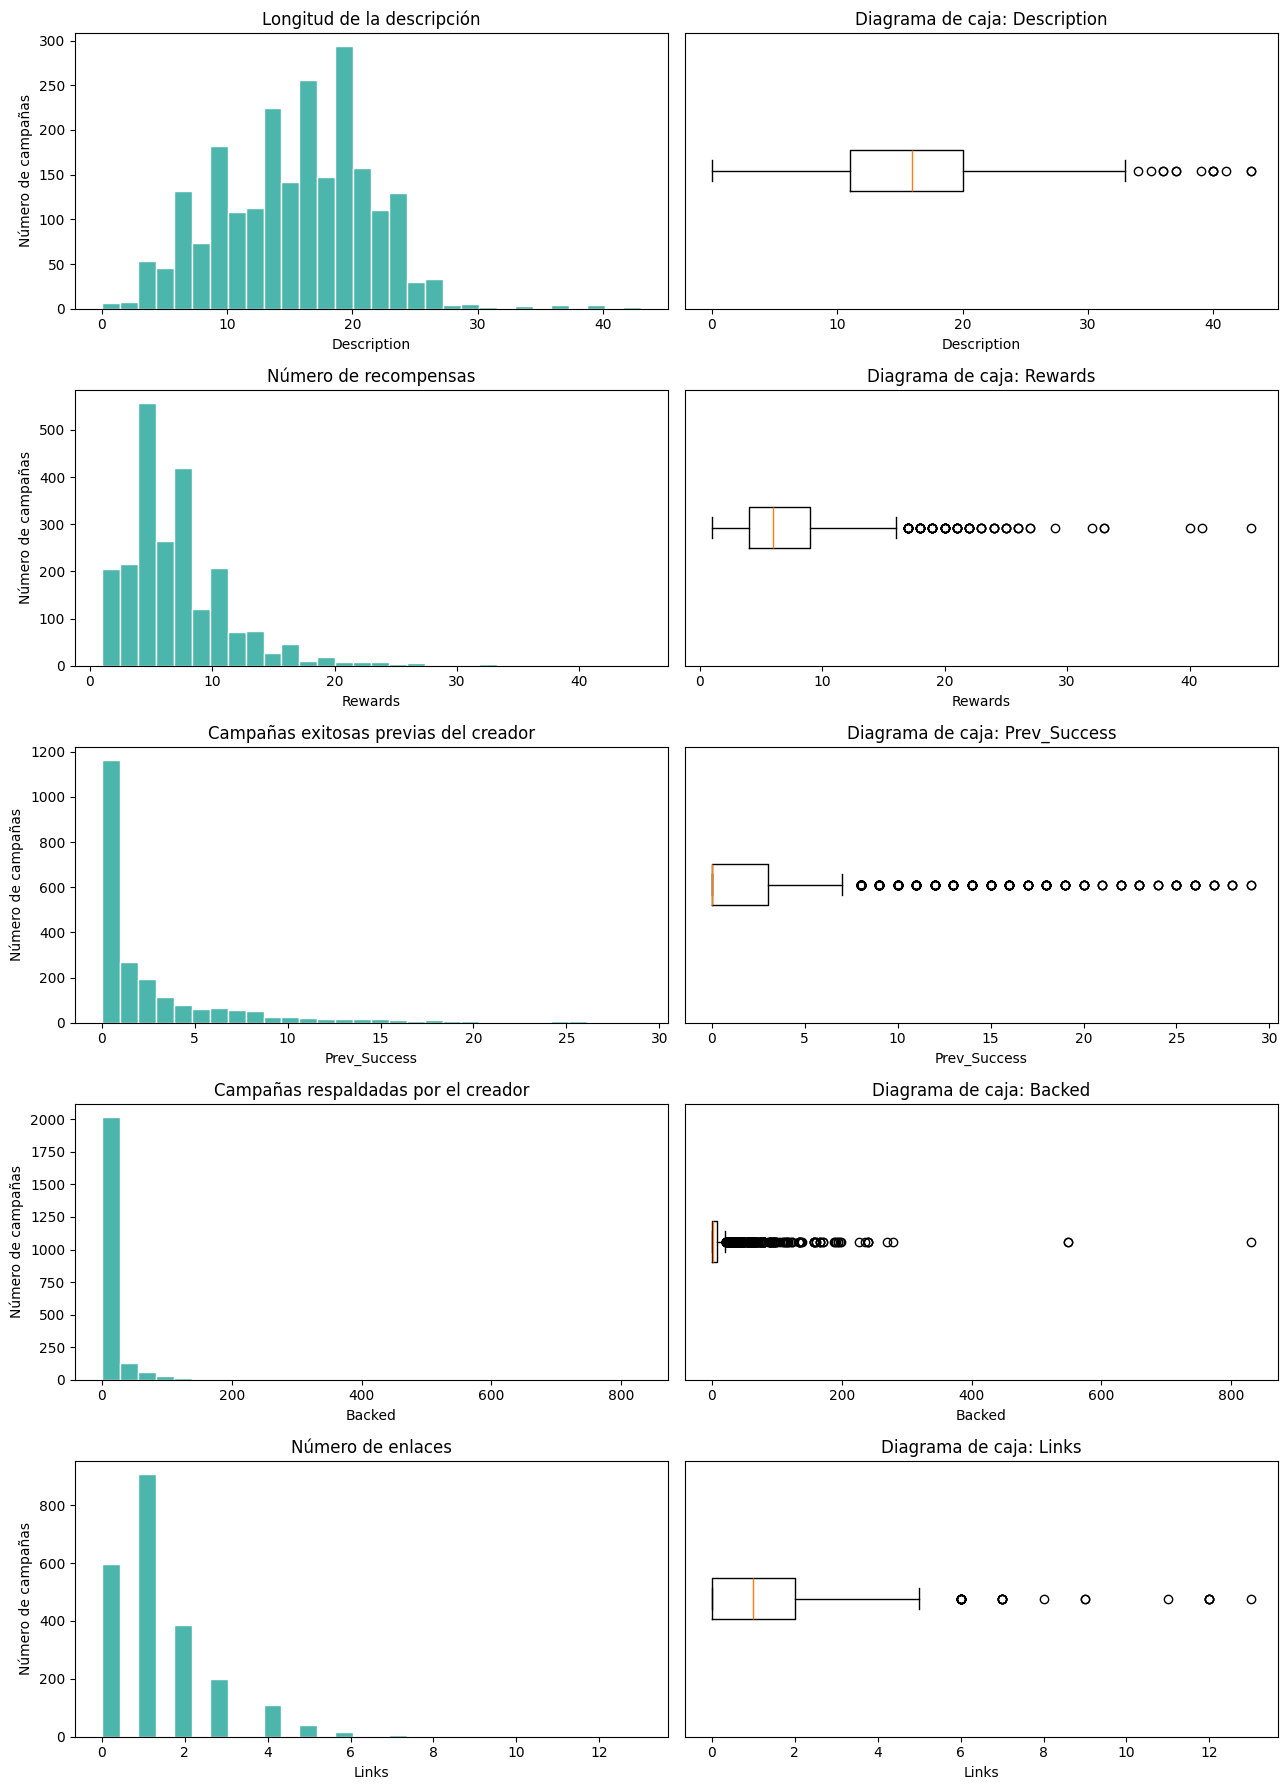

In [ ]:
import matplotlib.pyplot as plt

variables = {
    "Description": "Longitud de la descripción",
    "Rewards": "Número de recompensas",
    "Prev_Success": "Campañas exitosas previas del creador",
    "Backed": "Campañas respaldadas por el creador",
    "Links": "Número de enlaces"
}

fig, ejes = plt.subplots(5, 2, figsize=(13, 18))

for fila, (variable, titulo) in enumerate(variables.items()):
    datos = df[variable].dropna()

    ejes[fila, 0].hist(
        datos,
        bins=30,
        color="#4DB6AC",
        edgecolor="white"
    )
    ejes[fila, 0].set_title(titulo)
    ejes[fila, 0].set_xlabel(variable)
    ejes[fila, 0].set_ylabel("Número de campañas")

    ejes[fila, 1].boxplot(datos, vert=False)
    ejes[fila, 1].set_title(f"Diagrama de caja: {variable}")
    ejes[fila, 1].set_xlabel(variable)
    ejes[fila, 1].set_yticks([])

plt.tight_layout()
plt.show()

In [ ]:
exito_categoria = (
    df.groupby("Category")
    .agg(
        Campañas=("Success", "size"),
        Exitosas=("Success", "sum"),
        Porcentaje_exito=("Success", "mean")
    )
    .reset_index()
)

exito_categoria["No_exitosas"] = (
    exito_categoria["Campañas"] - exito_categoria["Exitosas"]
)

exito_categoria["Porcentaje_exito"] = (
    exito_categoria["Porcentaje_exito"] * 100
).round(2)

exito_categoria = exito_categoria.sort_values(
    "Porcentaje_exito", ascending=False
)

display(exito_categoria)

,Category,Campañas,Exitosas,Porcentaje_exito,No_exitosas
0,Creative Arts,337,295,87.54,42
4,Media & Entertainment,1494,1223,81.86,271
3,Literature & Journalism,159,125,78.62,34
1,Design,254,195,76.77,59
2,Food,28,17,60.71,11


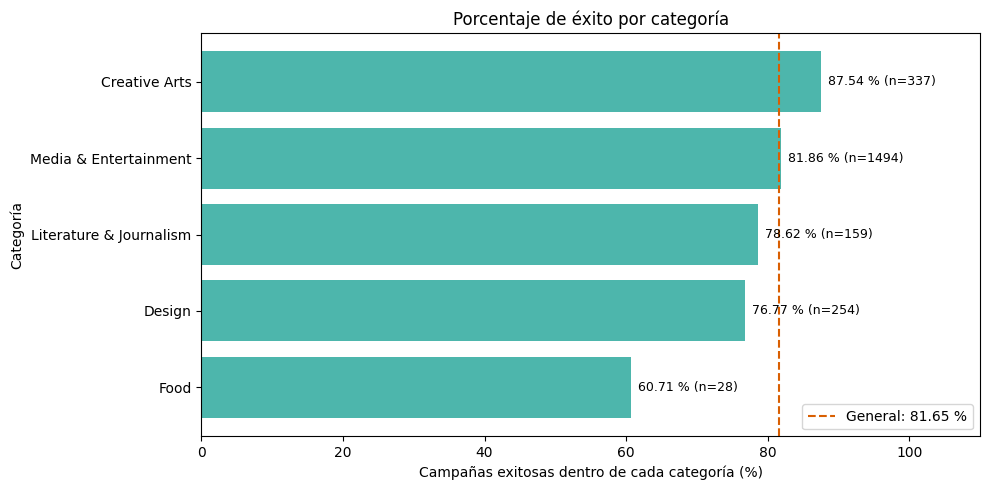

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    exito_categoria["Category"],
    exito_categoria["Porcentaje_exito"],
    color="#4DB6AC"
)

for barra, cantidad in zip(barras, exito_categoria["Campañas"]):
    ax.text(
        barra.get_width() + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{barra.get_width():.2f} % (n={cantidad})",
        va="center",
        fontsize=9
    )

porcentaje_general = df["Success"].mean() * 100

ax.axvline(
    porcentaje_general,
    color="#D95F02",
    linestyle="--",
    label=f"General: {porcentaje_general:.2f} %"
)

ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Campañas exitosas dentro de cada categoría (%)")
ax.set_ylabel("Categoría")
ax.set_title("Porcentaje de éxito por categoría")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [ ]:
tablas = []

for variable in ["Video_Header", "Videos_Bool", "Images_Bool"]:
    tabla = (
        df.groupby(variable)["Success"]
        .agg(Campañas="size", Exitosas="sum", Porcentaje_exito="mean")
        .reset_index()
        .rename(columns={variable: "Presencia"})
    )

    tabla["Presencia"] = tabla["Presencia"].map({0: "No", 1: "Sí"})
    tabla["Recurso"] = variable
    tabla["Porcentaje_exito"] = (
        tabla["Porcentaje_exito"] * 100
    ).round(2)

    tablas.append(tabla)

exito_multimedia = pd.concat(tablas, ignore_index=True)

display(exito_multimedia[
    ["Recurso", "Presencia", "Campañas", "Exitosas", "Porcentaje_exito"]
])

,Recurso,Presencia,Campañas,Exitosas,Porcentaje_exito
0,Video_Header,No,965,844,87.46
1,Video_Header,Sí,1307,1011,77.35
2,Videos_Bool,No,1883,1562,82.95
3,Videos_Bool,Sí,389,293,75.32
4,Images_Bool,No,123,90,73.17
5,Images_Bool,Sí,2149,1765,82.13


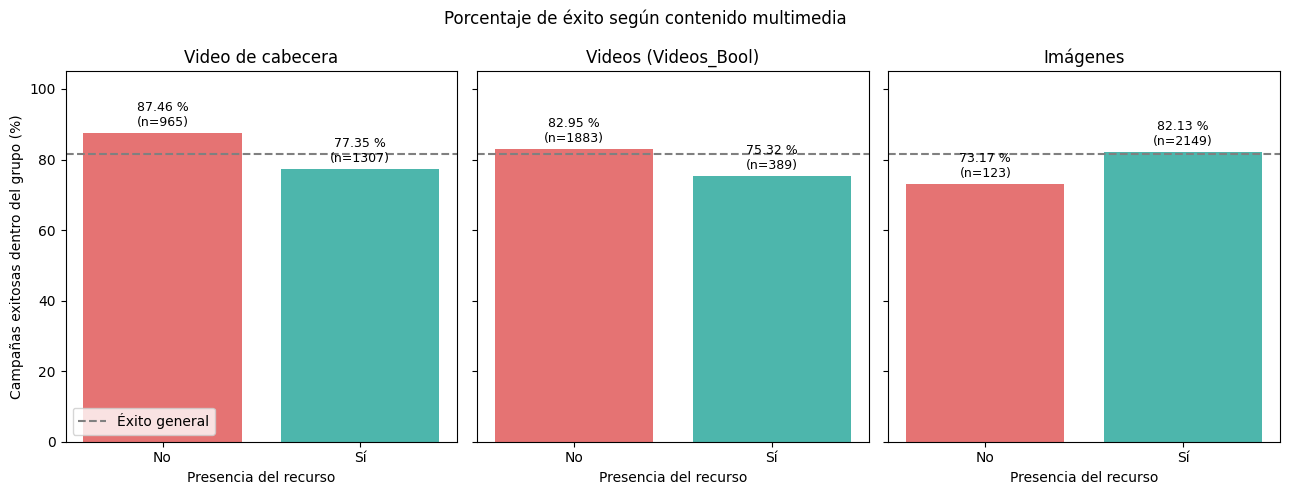

In [ ]:
import matplotlib.pyplot as plt

titulos = {
    "Video_Header": "Video de cabecera",
    "Videos_Bool": "Videos (Videos_Bool)",
    "Images_Bool": "Imágenes"
}

fig, ejes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, (variable, titulo) in zip(ejes, titulos.items()):
    datos = (
        exito_multimedia[
            exito_multimedia["Recurso"] == variable
        ]
        .set_index("Presencia")
        .reindex(["No", "Sí"])
    )

    barras = ax.bar(
        datos.index,
        datos["Porcentaje_exito"],
        color=["#E57373", "#4DB6AC"]
    )

    for barra, cantidad in zip(barras, datos["Campañas"]):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 2,
            f"{barra.get_height():.2f} %\n(n={int(cantidad)})",
            ha="center",
            fontsize=9
        )

    ax.axhline(
        df["Success"].mean() * 100,
        color="gray",
        linestyle="--",
        label="Éxito general"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Presencia del recurso")
    ax.set_ylim(0, 105)

ejes[0].set_ylabel("Campañas exitosas dentro del grupo (%)")
ejes[0].legend(loc="lower left")
fig.suptitle("Porcentaje de éxito según contenido multimedia")

plt.tight_layout()
plt.show()

In [ ]:
variables_comparar = [
    "Target",
    "Duration_Calendar",
    "Description",
    "Rewards",
    "Prev_Success",
    "Backed",
    "Links"
]

comparacion_numerica = (
    df.groupby("Success")[variables_comparar]
    .agg(["mean", "median"])
    .rename(index={0: "No exitosa", 1: "Exitosa"})
    .T
)

comparacion_numerica.index.names = ["Variable", "Medida"]
comparacion_numerica = comparacion_numerica.rename(
    index={"mean": "Media", "median": "Mediana"},
    level="Medida"
)

display(comparacion_numerica.round(2))

Success                    No exitosa  Exitosa
Variable          Medida                      
Target            Media      24257.45  4872.90
                  Mediana     9573.00  1204.68
Duration_Calendar Media         35.74    27.74
                  Mediana       30.00    30.00
Description       Media         15.25    15.58
                  Mediana       16.00    16.00
Rewards           Media          6.91     7.06
                  Mediana        6.00     6.00
Prev_Success      Media          0.45     3.22
                  Mediana        0.00     1.00
Backed            Media          4.23    13.53
                  Mediana        0.00     2.00
Links             Media          1.15     1.44
                  Mediana        1.00     1.00

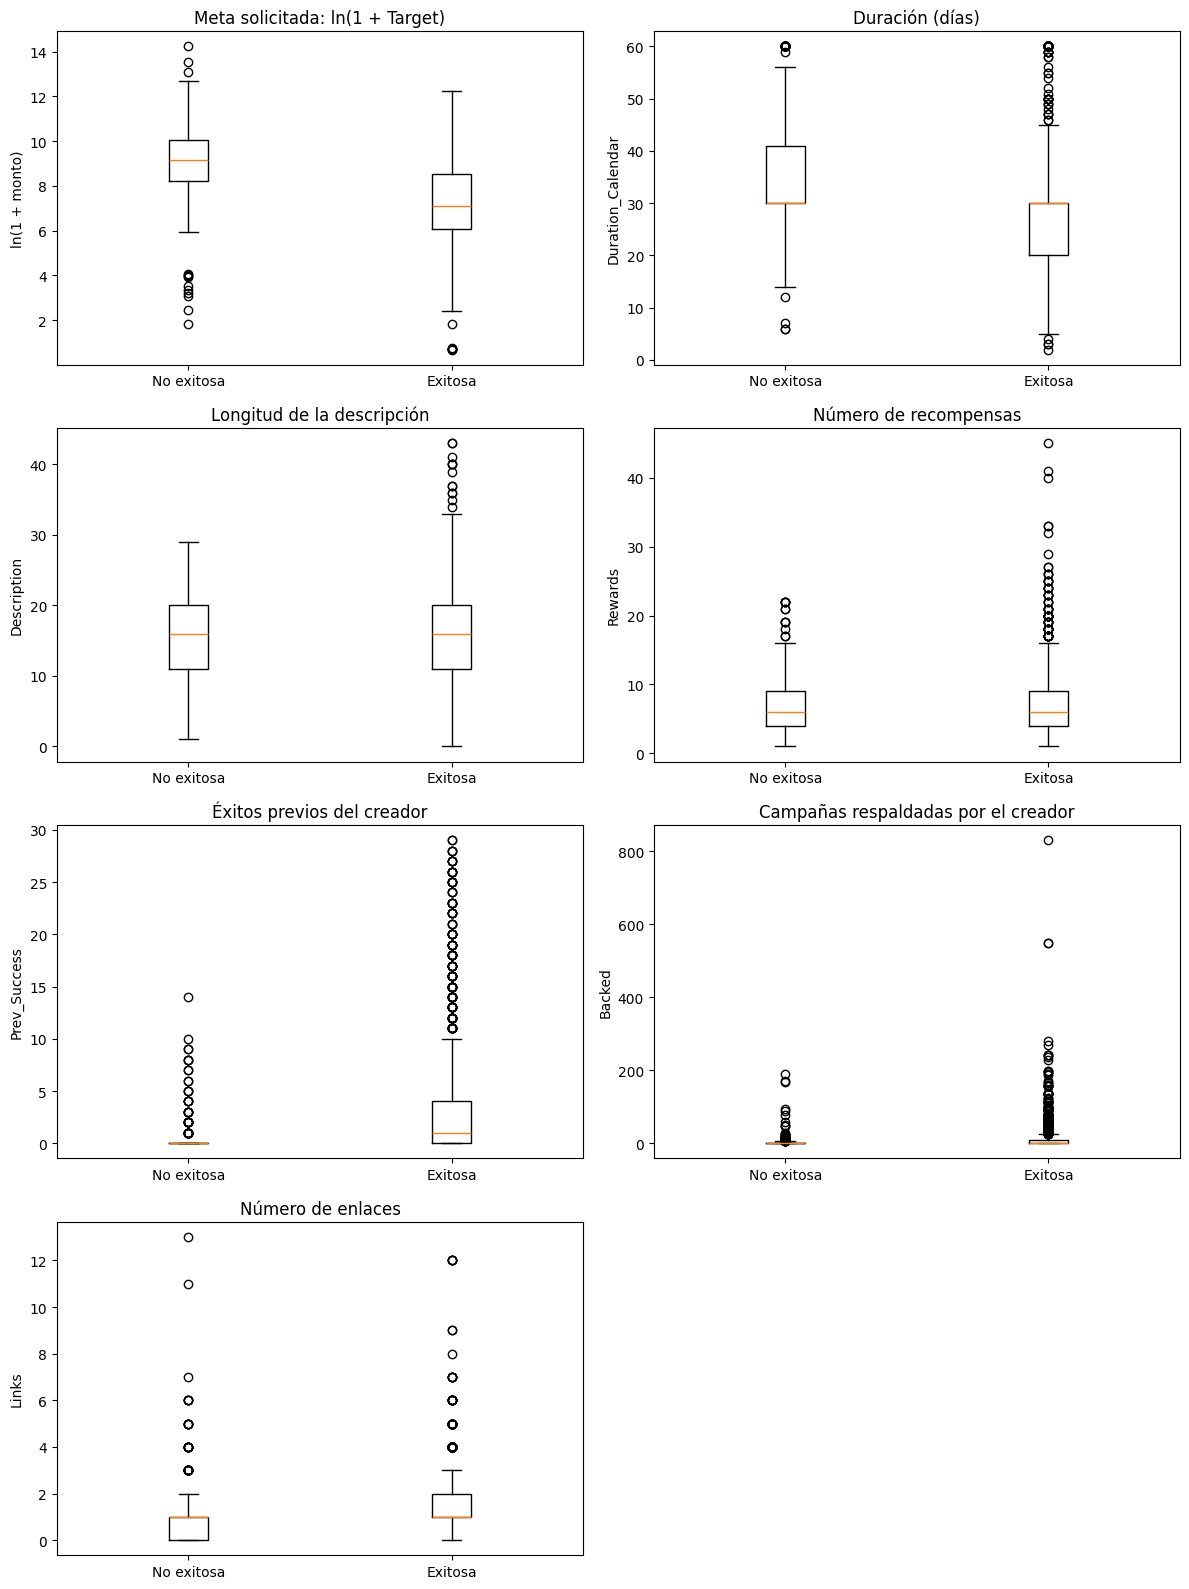

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

variables = {
    "Target": "Meta solicitada: ln(1 + Target)",
    "Duration_Calendar": "Duración (días)",
    "Description": "Longitud de la descripción",
    "Rewards": "Número de recompensas",
    "Prev_Success": "Éxitos previos del creador",
    "Backed": "Campañas respaldadas por el creador",
    "Links": "Número de enlaces"
}

fig, ejes = plt.subplots(4, 2, figsize=(12, 16))

for ax, (variable, titulo) in zip(ejes.flat, variables.items()):
    grupos = [
        df.loc[df["Success"] == resultado, variable].dropna()
        for resultado in [0, 1]
    ]

    if variable == "Target":
        grupos = [np.log1p(grupo) for grupo in grupos]

    ax.boxplot(grupos)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No exitosa", "Exitosa"])
    ax.set_title(titulo)
    ax.set_ylabel("ln(1 + monto)" if variable == "Target" else variable)

ejes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

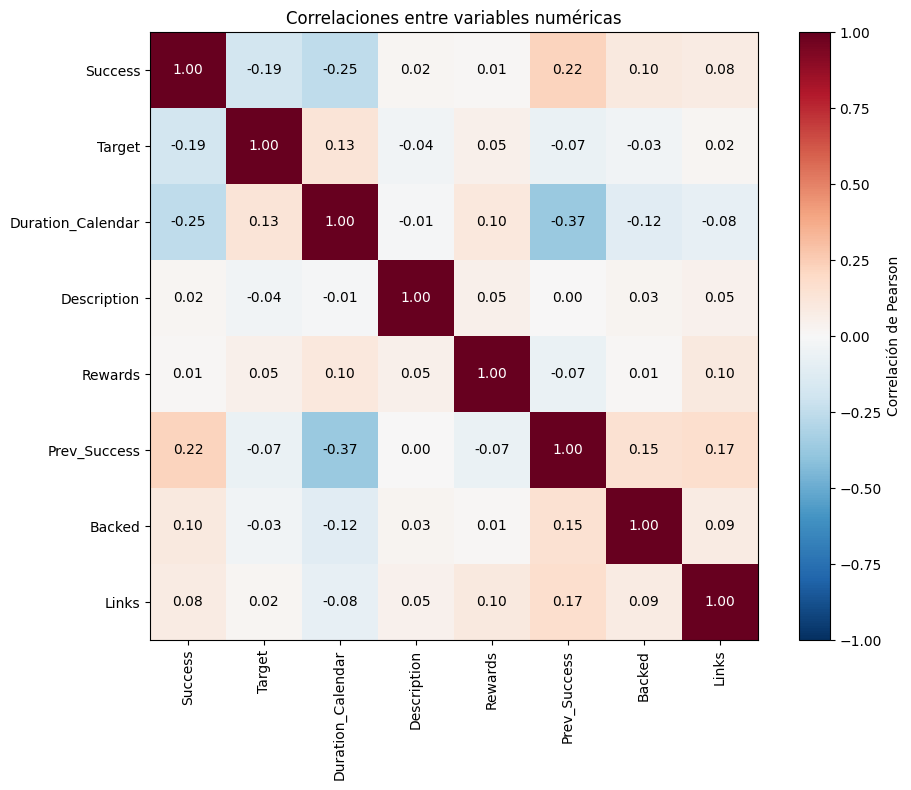

In [ ]:
import matplotlib.pyplot as plt

variables_correlacion = [
    "Success",
    "Target",
    "Duration_Calendar",
    "Description",
    "Rewards",
    "Prev_Success",
    "Backed",
    "Links"
]

correlaciones = df[variables_correlacion].corr()

fig, ax = plt.subplots(figsize=(10, 8))

imagen = ax.imshow(
    correlaciones,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(variables_correlacion)))
ax.set_yticks(range(len(variables_correlacion)))
ax.set_xticklabels(variables_correlacion, rotation=90)
ax.set_yticklabels(variables_correlacion)

for i in range(len(variables_correlacion)):
    for j in range(len(variables_correlacion)):
        valor = correlaciones.iloc[i, j]
        ax.text(
            j, i, f"{valor:.2f}",
            ha="center", va="center",
            color="white" if abs(valor) > 0.6 else "black"
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlaciones entre variables numéricas")

plt.tight_layout()
plt.show()

In [ ]:
indicadores = pd.DataFrame({
    "Indicador": [
        "Total de campañas",
        "Campañas exitosas",
        "Campañas no exitosas",
        "Porcentaje de éxito",
        "Financiamiento total recaudado",
        "Financiamiento mediano por campaña",
        "Meta mediana por campaña",
        "Duración mediana en días"
    ],
    "Valor": [
        len(df),
        df["Success"].eq(1).sum(),
        df["Success"].eq(0).sum(),
        df["Success"].eq(1).mean() * 100,
        df["Funding"].sum(),
        df["Funding"].median(),
        df["Target"].median(),
        df["Duration_Calendar"].median()
    ],
    "Unidad": [
        "Campañas",
        "Campañas",
        "Campañas",
        "%",
        "Unidad monetaria de Funding",
        "Unidad monetaria de Funding",
        "Unidad monetaria de Target",
        "Días"
    ]
})

display(indicadores.round(2))

,Indicador,Valor,Unidad
0,Total de campañas,2272.00,Campañas
1,Campañas exitosas,1855.00,Campañas
2,Campañas no exitosas,417.00,Campañas
3,Porcentaje de éxito,81.65,%
4,Financiamiento total recaudado,34457974.78,Unidad monetaria de Funding
5,Financiamiento mediano por campaña,3681.44,Unidad monetaria de Funding
6,Meta mediana por campaña,2103.20,Unidad monetaria de Target
7,Duración mediana en días,30.00,Días
